
# Практическая работа № 6. Классификация текстов

## Вариант B

### Цель работы
Реализовать обработку текстовых данных, выполнить очистку и нормализацию текста, преобразовать тексты в числовые признаки с помощью TF-IDF и обучить классификатор.

### Датасет
Women’s Clothing Reviews — отзывы покупателей об одежде.

### Этапы работы
1. Загрузка и анализ датасета.
2. Предобработка текстов.
3. Разделение данных на обучающую и тестовую выборки.
4. Векторизация TF-IDF.
5. Обучение классификатора Multinomial Naive Bayes.
6. Оценка качества модели.
7. Анализ пяти ошибок классификации.


In [1]:

import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

print("Библиотеки успешно импортированы!")


Библиотеки успешно импортированы!


In [3]:

with open("data/reviews.csv", "r", encoding="utf-8-sig") as file:
    for i in range(5):
        print(repr(file.readline()))


'review\tsentiment\n'
'качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......\tnegative\n'
'Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.\tnegative\n'
'Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на самом деле нет! Не рекомендую\tnegative\n'
'товар не пришел, продавец продлил защиту без моего согласия. от продавца одни обещания\tnegative\n'


In [5]:

df = pd.read_csv("data/reviews.csv", sep="\t")

print("Размер датасета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

display(df.head())


Размер датасета: (90000, 2)

Названия столбцов:
['review', 'sentiment']


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [6]:

print("Информация о датасете:")
df.info()

print("\nПропуски:")
print(df.isnull().sum())

print("\nКоличество отзывов каждого класса:")
print(df["sentiment"].value_counts())

print("\nПримеры отзывов:")
display(df[["review", "sentiment"]].head(3))


Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     90000 non-null  object
 1   sentiment  90000 non-null  object
dtypes: object(2)
memory usage: 1.4+ MB

Пропуски:
review       0
sentiment    0
dtype: int64

Количество отзывов каждого класса:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Примеры отзывов:


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative


In [7]:

print("Размер датасета:", df.shape)

print("\nКоличество пропусков:")
print(df[["review", "sentiment"]].isnull().sum())

print("\nРаспределение классов:")
print(df["sentiment"].value_counts())

print("\nПримеры отзывов:")
display(df[["review", "sentiment"]].head())


Размер датасета: (90000, 2)

Количество пропусков:
review       0
sentiment    0
dtype: int64

Распределение классов:
sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Примеры отзывов:


,review,sentiment
0,качество плохое пошив ужасный (горловина напер...,negative
1,"Товар отдали другому человеку, я не получила п...",negative
2,"Ужасная синтетика! Тонкая, ничего общего с пре...",negative
3,"товар не пришел, продавец продлил защиту без м...",negative
4,"Кофточка голая синтетика, носить не возможно.",negative


In [8]:

df = df.dropna(subset=["review", "sentiment"]).copy()

df["review"] = df["review"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

df = df[df["review"] != ""]
df = df.drop_duplicates(subset=["review", "sentiment"]).reset_index(drop=True)

print("Размер после очистки:", df.shape)
print("\nКоличество отзывов по классам:")
print(df["sentiment"].value_counts())


Размер после очистки: (87530, 2)

Количество отзывов по классам:
sentiment
positive    29363
negative    29135
neautral    29032
Name: count, dtype: int64


In [9]:

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

russian_stop_words = {
    "и", "в", "во", "не", "ни", "что", "он", "она", "оно", "они",
    "мы", "вы", "я", "ты", "меня", "мне", "мой", "моя", "мои",
    "твой", "его", "ее", "её", "их", "наш", "ваш", "это", "этот",
    "эта", "эти", "тот", "та", "те", "такой", "такая", "такие",
    "как", "а", "но", "да", "или", "если", "то", "же", "ли",
    "бы", "для", "по", "из", "у", "к", "от", "до", "за", "на",
    "с", "со", "о", "об", "при", "над", "под", "между", "через",
    "после", "перед", "был", "была", "были", "быть", "есть",
    "очень", "там", "тут", "здесь", "уже", "еще", "ещё",
    "только", "даже", "вот", "ну", "просто", "все", "всё",
    "так", "также", "чтобы", "который", "которая", "которые",
    "которое", "много", "более", "менее"
}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"_+", " ", text)

    tokens = text.split()
    tokens = [
        word for word in tokens
        if word not in russian_stop_words
        and len(word) > 1
    ]

    return " ".join(tokens)

print("Функция очистки создана!")


Функция очистки создана!


In [10]:

df["clean_review"] = df["review"].apply(clean_text)

for i in range(3):
    print("Исходный текст:")
    print(df["review"].iloc[i])

    print("\nОчищенный текст:")
    print(df["clean_review"].iloc[i])

    print("\nТональность:", df["sentiment"].iloc[i])
    print("-" * 70)


Исходный текст:
качество плохое пошив ужасный (горловина наперекос) Фото не соответствует Ткань ужасная рисунок блеклый маленький рукав не такой УЖАС!!!!! не стоит за такие деньги г.......

Очищенный текст:
качество плохое пошив ужасный горловина наперекос фото соответствует ткань ужасная рисунок блеклый маленький рукав ужас стоит деньги

Тональность: negative
----------------------------------------------------------------------
Исходный текст:
Товар отдали другому человеку, я не получила посылку. Ладно хоть деньги вернули.

Очищенный текст:
товар отдали другому человеку получила посылку ладно хоть деньги вернули

Тональность: negative
----------------------------------------------------------------------
Исходный текст:
Ужасная синтетика! Тонкая, ничего общего с представленной картинкой, не яркая, рисунок растянут и тусклый, впрочем как и сама кофта- мешок! На картинке кажется приталенной на самом деле нет! Не рекомендую

Очищенный текст:
ужасная синтетика тонкая ничего общего предст

In [11]:

X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка:", X_test.shape[0])

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts())


Обучающая выборка: 70024
Тестовая выборка: 17506

Классы в обучающей выборке:
sentiment
positive    23490
negative    23308
neautral    23226
Name: count, dtype: int64

Классы в тестовой выборке:
sentiment
positive    5873
negative    5827
neautral    5806
Name: count, dtype: int64


In [12]:

tfidf = TfidfVectorizer(
    min_df=3,
    max_df=0.9,
    max_features=30000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Размер обучающей матрицы:", X_train_tfidf.shape)
print("Размер тестовой матрицы:", X_test_tfidf.shape)
print("Размер словаря:", len(tfidf.vocabulary_))


Размер обучающей матрицы: (70024, 30000)
Размер тестовой матрицы: (17506, 30000)
Размер словаря: 30000


In [13]:

model = MultinomialNB(alpha=0.5)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Модель обучена!")
print("Количество предсказаний:", len(y_pred))


Модель обучена!
Количество предсказаний: 17506


In [14]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nОтчёт по классам:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy:  0.7205
Precision: 0.7280
Recall:    0.7201
F1-score:  0.7211

Отчёт по классам:
              precision    recall  f1-score   support

    neautral       0.60      0.69      0.64      5806
    negative       0.75      0.62      0.68      5827
    positive       0.84      0.84      0.84      5873

    accuracy                           0.72     17506
   macro avg       0.73      0.72      0.72     17506
weighted avg       0.73      0.72      0.72     17506



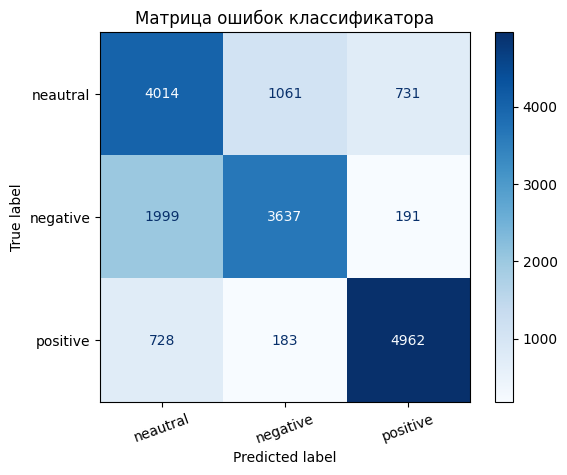

In [15]:

labels = model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Матрица ошибок классификатора")
plt.xticks(rotation=20)
plt.show()


In [16]:

errors = pd.DataFrame({
    "Исходный текст": X_test.reset_index(drop=True),
    "Правильная тональность": y_test.reset_index(drop=True),
    "Предсказанная тональность": y_pred
})

errors = errors[
    errors["Правильная тональность"] != errors["Предсказанная тональность"]
].reset_index(drop=True)

print("Всего ошибок:", len(errors))

display(errors.head(5))


Всего ошибок: 4893


,Исходный текст,Правильная тональность,Предсказанная тональность
0,размером непонятки,neautral,positive
1,заказ шел месяц сломана одна застёжка крючок и...,neautral,negative
2,противный материал синтетическая марля пипец к...,negative,neautral
3,пальто супер нечего сказать недели было достав...,neautral,positive
4,покупала распродажу первые минуты осталось огр...,positive,negative


In [17]:

for i, row in errors.head(5).iterrows():
    print(f"ОШИБКА {i + 1}")
    print("Текст:", row["Исходный текст"])
    print("Правильный класс:", row["Правильная тональность"])
    print("Предсказанный класс:", row["Предсказанная тональность"])
    print(
        "Возможная причина: модель могла не распознать контекст, "
        "иронию, отрицание или неоднозначные слова."
    )
    print("-" * 80)


ОШИБКА 1
Текст: размером непонятки
Правильный класс: neautral
Предсказанный класс: positive
Возможная причина: модель могла не распознать контекст, иронию, отрицание или неоднозначные слова.
--------------------------------------------------------------------------------
ОШИБКА 2
Текст: заказ шел месяц сломана одна застёжка крючок использованию подлежит больше заказывать буду деньги хоть болшие выкинуты ветер
Правильный класс: neautral
Предсказанный класс: negative
Возможная причина: модель могла не распознать контекст, иронию, отрицание или неоднозначные слова.
--------------------------------------------------------------------------------
ОШИБКА 3
Текст: противный материал синтетическая марля пипец какой прозрачный хотела работу блузку белую хрен куда оденешь размер мал
Правильный класс: negative
Предсказанный класс: neautral
Возможная причина: модель могла не распознать контекст, иронию, отрицание или неоднозначные слова.
------------------------------------------------------------


## Выводы

В ходе практической работы был реализован пайплайн классификации русскоязычных отзывов.

На этапе предобработки тексты приводились к нижнему регистру, очищались от ссылок, цифр и пунктуации. Также выполнялось удаление стоп-слов. Отрицания «не» и «ни» сохранялись, поскольку они могут влиять на тональность отзыва.

Для преобразования текстов в числовые признаки использовался TF-IDF с параметрами min_df, max_df, max_features и ngram_range.

Данные были разделены на обучающую и тестовую выборки до обучения векторизатора. TF-IDF обучался только на обучающей выборке, что предотвращает утечку информации из тестовых данных.

Для классификации применялся Multinomial Naive Bayes. Качество оценивалось с помощью Accuracy, Precision, Recall и F1-score. Также была построена матрица ошибок.

Дополнительно были рассмотрены пять ошибочно классифицированных отзывов. Возможными причинами ошибок могут быть контекст, ирония, отрицания и неоднозначность слов.

Таким образом, были изучены основные этапы обработки текстов и построения классификатора тональности.
